In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import xml.etree.ElementTree as ET
import pathlib, os

IMG_SIZE = 224
DATA_DIR = pathlib.Path('/content/data')
print(list(DATA_DIR.glob('*')))

[PosixPath('/content/data/test_zip'), PosixPath('/content/data/train_zip')]


In [ ]:
def parse_annotation(xml_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()
    size = root.find('size')
    w, h = int(size.find('width').text), int(size.find('height').text)
    obj = root.find('object')  # dataset has one primary object per image
    name = obj.find('name').text
    bnd = obj.find('bndbox')
    xmin = int(float(bnd.find('xmin').text)); ymin = int(float(bnd.find('ymin').text))
    xmax = int(float(bnd.find('xmax').text)); ymax = int(float(bnd.find('ymax').text))
    return name, (xmin, ymin, xmax, ymax), (w, h)

xml_files = sorted(DATA_DIR.rglob('*.xml'))
print(f"Found {len(xml_files)} annotation files")
print(parse_annotation(xml_files[0]))

Found 300 annotation files
('apple', (71, 60, 175, 164), (300, 229))


In [ ]:

classes = sorted(set(parse_annotation(x)[0] for x in xml_files))
class_to_idx = {c: i for i, c in enumerate(classes)}
print("Classes:", classes)

images, bboxes, labels = [], [], []
skipped = 0

for xml_path in xml_files:
    img_path = xml_path.with_suffix('.jpg')
    if not img_path.exists():
        img_path = xml_path.with_suffix('.png')
        if not img_path.exists():
            skipped += 1
            continue

    name, (xmin, ymin, xmax, ymax), (w, h) = parse_annotation(xml_path)

    img_raw = tf.io.read_file(str(img_path))
    img_decoded = tf.image.decode_image(img_raw, channels=3, expand_animations=False)
    real_h, real_w = img_decoded.shape[0], img_decoded.shape[1]

    # use the real image dimensions instead of the XML's <size> tag
    if real_w == 0 or real_h == 0:
        skipped += 1
        continue

    img = tf.image.resize(img_decoded, (IMG_SIZE, IMG_SIZE)) / 255.0
    bbox_norm = [xmin / real_w, ymin / real_h, xmax / real_w, ymax / real_h]

    images.append(img.numpy())
    bboxes.append(bbox_norm)
    labels.append(class_to_idx[name])

images = np.array(images, dtype=np.float32)
bboxes = np.array(bboxes, dtype=np.float32)
labels = np.array(labels, dtype=np.int32)
print(f"Loaded {len(images)} samples, skipped {skipped} broken files")
print(images.shape, bboxes.shape, labels.shape)

Classes: ['apple', 'banana', 'orange']
Loaded 300 samples, skipped 0 broken files
(300, 224, 224, 3) (300, 4) (300,)


In [ ]:
from sklearn.model_selection import train_test_split

(train_imgs, val_imgs,
 train_boxes, val_boxes,
 train_labels, val_labels) = train_test_split(
    images, bboxes, labels, test_size=0.2, random_state=42, stratify=labels
)

In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet'
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(128, activation='relu')(x)

class_output = tf.keras.layers.Dense(len(classes), activation='softmax', name='class_output')(x)
bbox_output = tf.keras.layers.Dense(4, activation='sigmoid', name='bbox_output')(x)

model = tf.keras.Model(inputs=inputs, outputs=[class_output, bbox_output])

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss={'class_output': 'sparse_categorical_crossentropy', 'bbox_output': 'mse'},
    loss_weights={'class_output': 1.0, 'bbox_output': 5.0},
    metrics={'class_output': 'accuracy', 'bbox_output': 'mae'}
)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_2… │ (None, 7, 7,      │  2,257,984 │ input_layer_1[0]… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    163,968 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_output        │ (None, 3)         │        387 │ dense[0][0]       │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bbox_output (Dense) │ (None, 4)         │        516 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,422,855 (9.24 MB)

 Trainable params: 164,871 (644.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# 7. Train
history = model.fit(
    train_imgs,
    {'class_output': train_labels, 'bbox_output': train_boxes},
    validation_data=(val_imgs, {'class_output': val_labels, 'bbox_output': val_boxes}),
    epochs=15,
    batch_size=16
)

Epoch 1/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 35s 1s/step - bbox_output_loss: 0.0499 - bbox_output_mae: 0.1692 - class_output_accuracy: 0.8000 - class_output_loss: 0.4245 - loss: 0.6739 - val_bbox_output_loss: 0.0433 - val_bbox_output_mae: 0.1521 - val_class_output_accuracy: 0.9833 - val_class_output_loss: 0.0930 - val_loss: 0.3029
Epoch 2/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - bbox_output_loss: 0.0308 - bbox_output_mae: 0.1321 - class_output_accuracy: 0.9833 - class_output_loss: 0.0575 - loss: 0.2115 - val_bbox_output_loss: 0.0294 - val_bbox_output_mae: 0.1345 - val_class_output_accuracy: 0.9833 - val_class_output_loss: 0.0792 - val_loss: 0.2133
Epoch 3/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - bbox_output_loss: 0.0227 - bbox_output_mae: 0.1133 - class_output_accuracy: 0.9958 - class_output_loss: 0.0248 - loss: 0.1381 - val_bbox_output_loss: 0.0274 - val_bbox_output_mae: 0.1297 - val_class_output_accuracy: 0.9833 - val_class_output_loss: 0.0733 - val_loss: 0.1993
Epoch 4/15
15/15 ━━━

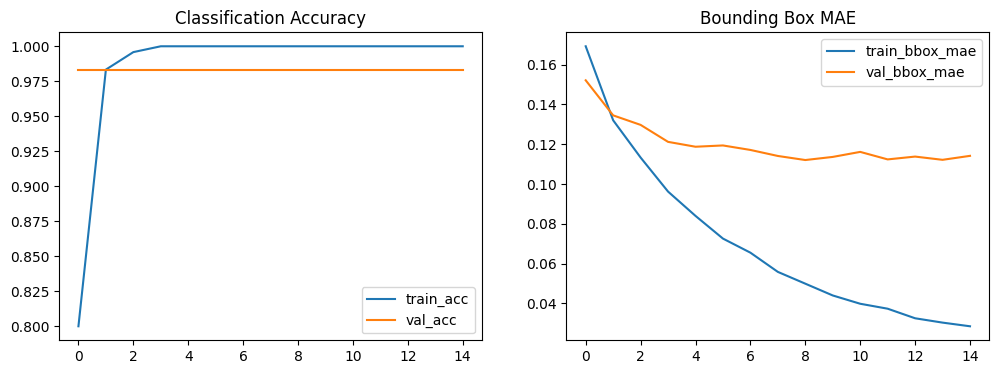

In [ ]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['class_output_accuracy'], label='train_acc')
plt.plot(history.history['val_class_output_accuracy'], label='val_acc')
plt.legend(); plt.title('Classification Accuracy')

plt.subplot(1,2,2)
plt.plot(history.history['bbox_output_mae'], label='train_bbox_mae')
plt.plot(history.history['val_bbox_output_mae'], label='val_bbox_mae')
plt.legend(); plt.title('Bounding Box MAE')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step


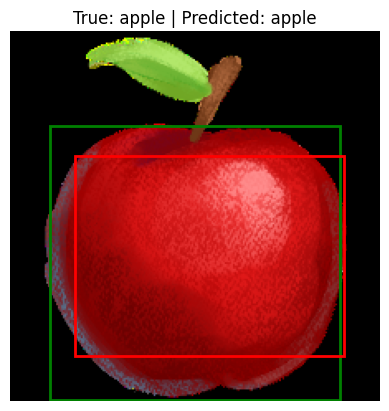

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


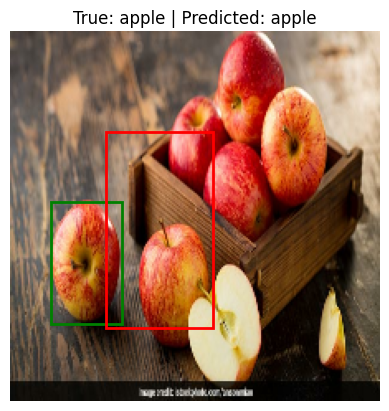

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


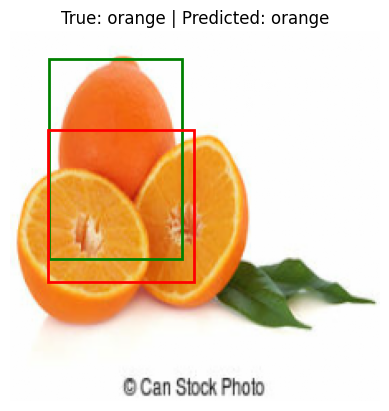

In [ ]:
def show_prediction(idx):
    img = val_imgs[idx]
    true_label = classes[val_labels[idx]]
    true_box = val_boxes[idx]

    pred_class, pred_box = model.predict(np.expand_dims(img, 0))
    pred_label = classes[np.argmax(pred_class[0])]
    pred_box = pred_box[0]

    fig, ax = plt.subplots(1)
    ax.imshow(img)
    h, w = img.shape[0], img.shape[1]

    # ground truth box (green)
    xmin, ymin, xmax, ymax = true_box * [w, h, w, h]
    ax.add_patch(patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
                                    linewidth=2, edgecolor='g', facecolor='none', label='true'))
    # predicted box (red)
    xmin, ymin, xmax, ymax = pred_box * [w, h, w, h]
    ax.add_patch(patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
                                    linewidth=2, edgecolor='r', facecolor='none', label='pred'))

    ax.set_title(f"True: {true_label} | Predicted: {pred_label}")
    ax.axis('off')
    plt.show()

for i in range(3):
    show_prediction(i)

In [ ]:
model.save('fruit_object_detector.h5')
print("Saved as fruit_object_detector.h5")

Saved as fruit_object_detector.h5
